In [ ]:
import glob
import os
import re
import numpy as np
import matplotlib.pyplot as plt
from shell_functions import shells_from_model, shell_vectors

A = 2.867
NSHELLS = 25
OUTPUT = "main/data/structures_20/refined_08/js_from_yell"
os.makedirs(OUTPUT, exist_ok=True)

cif_paths = sorted(glob.glob("main/data/structures_20/refined_08/*.cif"))
KT_MC = 0.200 # temperature the frames' MC ran at (same units as J)
J_SPIN = [0.03404208146199999, 0.021124325030900004, -0.004866611544200001, -0.0002460455964000001, 0.0024165038549999996, 0.0033137225009999996, 0.0055816756000000006, 0.001650310686, -0.0023729409847, -0.002369276486, -0.0054594407164999985, -0.0015049510957000003]
# J_NEW = [-1.08077600e-04, -2.07541501e-04, -1.11508256e-04,  5.45501996e-05,
    #    -1.99140842e-04,  8.51248378e-05,  1.20931067e-04,  6.95882226e-05,
    #    -9.50155117e-06, -1.68160637e-04, -4.16289159e-05,  6.85268035e-05]
# J_SPIN = [a+b for a, b in zip(J_SPIN, J_NEW)]
# J_SPIN

In [2]:
shell_keys, shell_r = shells_from_model('model.txt', NSHELLS)
vectors_of_shell = [shell_vectors(key) for key in shell_keys]
multiplicity = np.array([len(v) for v in vectors_of_shell], float)

# for n, (key, r) in enumerate(zip(shell_keys, shell_r), 1):
#     print(f'{n:3d}  {str(tuple(c / 2 for c in key)):>18}  r={r:6.3f} A  mult={len(vectors_of_shell[n-1])}')

In [3]:
# read cif
def read_cif(path):
    # returns (cell edge, [(element, fx, fy, fz), ...]); minimal parser
    text = open(path).read()
    edge = float(re.search(r'_cell_length_a\s+([\d.]+)', text).group(1))
    atoms = re.findall(r'^\s*(Fe|Al)\s+\S+\s+\S+\s+([\d.eE+-]+)\s+([\d.eE+-]+)\s+([\d.eE+-]+)',
                       text, re.MULTILINE)
    return edge, [(el, float(x), float(y), float(z)) for el, x, y, z in atoms]

# turn into 1s and 0s matrix with doubled coordinates
def occupancy_matrix(edge, atoms):
    # (2L)^3 array: 1=Fe, 0=Al or empty grid point (in doubled coords)
    L = round(edge / A)
    grid = np.zeros((2 * L,) * 3)
    for el, x, y, z in atoms:
        if el == 'Fe':
            i, j, k = (round(f * 2 * L) % (2 * L) for f in (x, y, z))
            grid[i, j, k] = 1.0
    return grid, 2 * L ** 3

# compute dp for one configuration
def dp_one_config(grid, nsites, c):
    # dp_m = P(FeFe at shell m) - c^2, via roll products over each shell
    dp = np.empty(NSHELLS)
    N_FeFe = np.empty(NSHELLS, dtype=int)
    for m, vectors in enumerate(vectors_of_shell):
        pairs = sum(np.sum(grid * np.roll(grid, (-d[0], -d[1], -d[2]), (0, 1, 2)))
                    for d in vectors) # of all FeFe pairs in this shell
        dp[m] = pairs / (len(vectors) * nsites) - c ** 2 # normalized by total pairs and subtract c^2
        N_FeFe[m] = pairs // 2
    return dp, N_FeFe

In [4]:
dp_list, pairs_list = [], []

# process each structure and compute dp
for path in cif_paths:
    grid, nsites = occupancy_matrix(*read_cif(path))
    c = grid.sum() / nsites
    dp, pairs = dp_one_config(grid, nsites, c)
    
    dp_list.append(dp)
    pairs_list.append(pairs)

# convert results to 2D NumPy arrays
dp_per_config = np.array(dp_list)
pairs_per_config = np.array(pairs_list)

print(dp_per_config.shape, f'nsites={nsites} c={c:.3f}')

(300, 25) nsites=16000 c=0.800


In [5]:
# differences between MC and Yell refinement; also compute sem
values = dict(re.findall(r'sub_(\d+)_AlAl=([-\d.eE+]+);',
                         open('refined_parameters.txt').read()))
dp_yell = np.array([float(values[str(n)]) for n in range(1, NSHELLS + 1)])

dp_mc = dp_per_config.mean(axis=0)
sem = dp_per_config.std(axis=0, ddof=1) / np.sqrt(len(dp_per_config))
dp_diff = dp_yell - dp_mc

print(f"{'sh':>3} {'dp_MC':>10} {'dp_Yell':>10} {'diff':>10} {'diff^2':>10} {'diff/sem':>9}")
for n in range(NSHELLS):
    print(f'{n+1:3d} {dp_mc[n]:+10.6f} {dp_yell[n]:+10.6f} {dp_diff[n]:+10.6f} '
          f'{dp_diff[n]**2:+10.6f} {dp_diff[n]/sem[n]:+9.1f}')

 sh      dp_MC    dp_Yell       diff     diff^2  diff/sem
  1  -0.015257  -0.011657  +0.003600  +0.000013    +117.8
  2  -0.004690  -0.008280  -0.003590  +0.000013     -82.8
  3  +0.004798  +0.011361  +0.006562  +0.000043    +180.3
  4  +0.001501  +0.001576  +0.000075  +0.000000      +3.6
  5  -0.001799  -0.001828  -0.000029  +0.000000      -0.8
  6  -0.001560  -0.001027  +0.000533  +0.000000     +12.5
  7  -0.000462  -0.004232  -0.003769  +0.000014    -172.0
  8  -0.000990  -0.003165  -0.002175  +0.000005     -90.8
  9  -0.000145  +0.003889  +0.004033  +0.000016    +171.3
 10  +0.000500  +0.001065  +0.000564  +0.000000     +26.8
 11  +0.002244  +0.003457  +0.001213  +0.000001     +30.7
 12  +0.000075  +0.004159  +0.004084  +0.000017    +123.8
 13  +0.000218  +0.000163  -0.000055  +0.000000      -3.3
 14  -0.000015  -0.000674  -0.000659  +0.000000     -15.8
 15  -0.000417  -0.002375  -0.001958  +0.000004     -84.7
 16  -0.000117  +0.000537  +0.000654  +0.000000     +27.8
 17  -0.000145

norm : 0.011584016277804136
worst shells : [ 3 12  9  7  1]


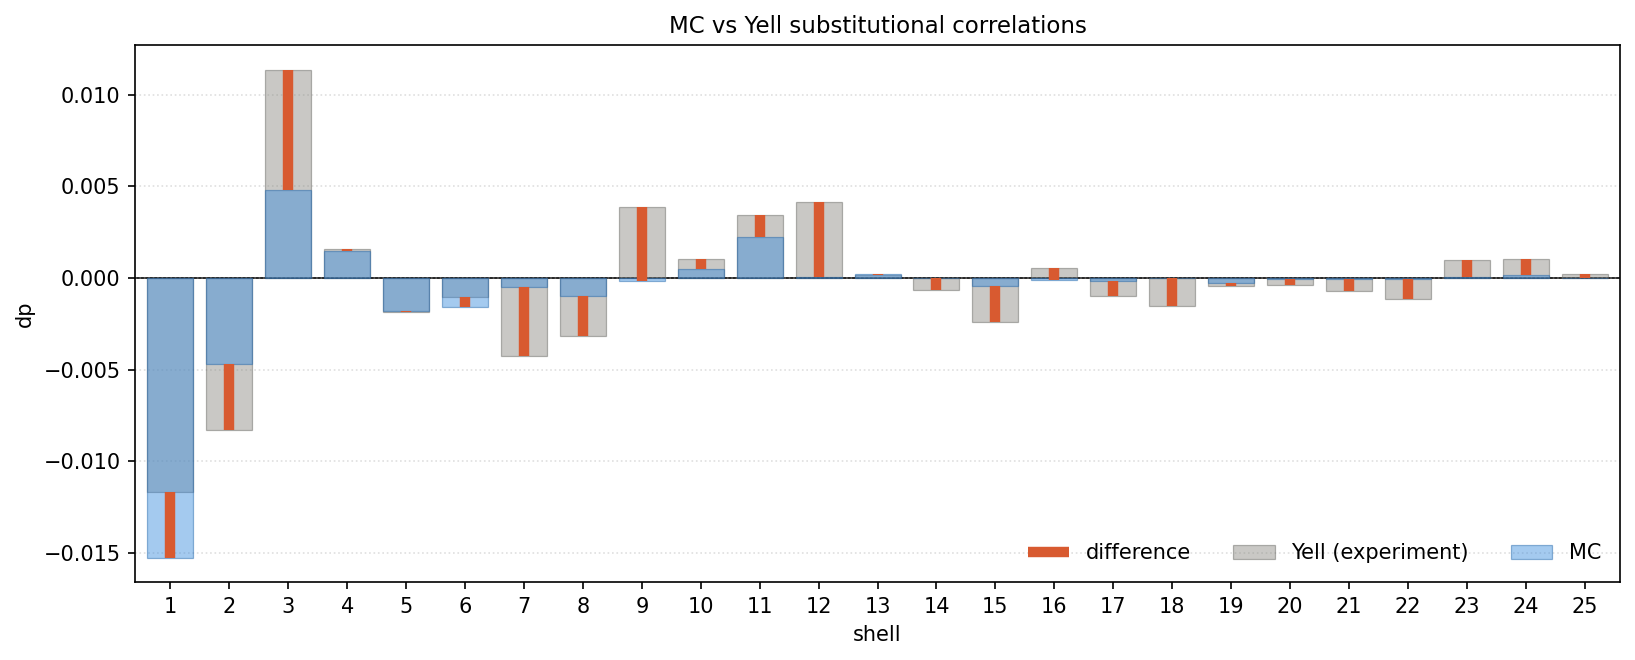

In [6]:
shells = np.arange(1, len(dp_mc) + 1)

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=150)

ax.bar(shells, dp_yell, width=0.78, color='#888780', alpha=0.45,
       edgecolor='#5F5E5A', linewidth=0.6, label='Yell (experiment)', zorder=2)
ax.bar(shells, dp_mc, width=0.78, color='#378ADD', alpha=0.45,
       edgecolor='#185FA5', linewidth=0.6, label='MC', zorder=3)

# red connectors make the residual pop
ax.vlines(shells, dp_yell, dp_mc, color='#D85A30', linewidth=5, zorder=4,
          label='difference')

ax.axhline(0, color='k', linewidth=0.8, zorder=1)
ax.set_xlabel('shell')
ax.set_ylabel('dp')
ax.set_xticks(shells)
ax.set_xlim(0.4, len(shells) + 0.6)
ax.legend(frameon=False, ncol=3, loc='lower right')
ax.grid(axis='y', linestyle=':', alpha=0.4, zorder=0)
ax.set_title('MC vs Yell substitutional correlations', fontsize=11)

plt.tight_layout()
# plt.savefig('dp_comparison.png', dpi=150, bbox_inches='tight')
print('norm :', f'{np.sqrt(((dp_diff)**2).sum())}')
print('worst shells :', (np.argsort(-np.abs(dp_diff))[:5] + 1))
# print('saved dp_comparison.png')


In [7]:
# energy of each configuration from pair counts and J:  E = sum_n J_n * N_FeFe_n  (kT units)
J_OC = 4 * np.pad(np.asarray(J_SPIN, float), (0, NSHELLS - len(J_SPIN))) # spin->occupancy (x4), pad with zeros

E_shell_per_config = pairs_per_config * J_OC   # (n_configs, NSHELLS): J_n * N_n, per shell
E_total_per_config = pairs_per_config @ J_OC   # (n_configs,): E of each configuration

np.savez(f'{OUTPUT}/dp_energy_table.npz', dp_per_config=dp_per_config,
         N_FeFe=pairs_per_config, J_OC=J_OC,
         E_shell_per_config=E_shell_per_config, E_total_per_config=E_total_per_config,
         dp_yell=dp_yell, dp_diff=dp_diff, multiplicity=multiplicity,
         shell_r=shell_r, nsites=nsites, c=c)
header = ','.join(f'shell_{n}' for n in range(1, NSHELLS + 1))
np.savetxt(f'{OUTPUT}/dp_per_config.csv', dp_per_config, delimiter=',', header=header, comments='')
np.savetxt(f'{OUTPUT}/pair_counts_FeFe.csv', pairs_per_config, delimiter=',', header=header, comments='', fmt='%d')
np.savetxt(f'{OUTPUT}/energy_total_per_config.csv', E_total_per_config, delimiter=',', header='E_total', comments='')

# print('E_total:', E_total_per_config[:])
print('spread over ensemble   : mean', f'{E_total_per_config.mean():.1f}',
      ' std', f'{E_total_per_config.std(ddof=1):.1f}')

spread over ensemble   : mean 8547.4  std 5.7


In [8]:
# calculate susceptibility matrix:  chi_{l,k} = d(dp_l)/d(J_k) = -4/kT * ( <dp_l N_k> - <dp_l><N_k> )
susceptibility = np.zeros((NSHELLS, len(J_SPIN)))
for l in range(NSHELLS):
    for k in range(len(J_SPIN)):
        susceptibility[l, k] = -4/KT_MC*(
            (np.mean(dp_per_config[:, l]*pairs_per_config[:, k]))
            -np.mean(dp_per_config[:, l])*np.mean(pairs_per_config[:, k])
            )   

In [9]:
# solve for J with damping factor
A = susceptibility
LAMBDA = 1.0
np.linalg.solve(A.T @ A + LAMBDA * np.diag(np.diag(A.T @ A)), A.T @ dp_diff)

array([-0.0021993 ,  0.00269944, -0.00242015,  0.00070405,  0.00039623,
       -0.00021297,  0.00294142,  0.00122316, -0.00232459, -0.00049083,
       -0.00122288, -0.00244787])